# Análisis de la red de transferencias de tokens en Ethereum mediante Teoría de Grafos

**Universidad Industrial de Santander (UIS)**  
**Curso:** Teoría de Grafos  
**Proyecto final:** aplicación de algoritmos sobre grafos a un dataset real

**Integrantes:**
- Emerson Ballesteros Diaz — Tarea 1
- Jhon Arciniegas — Tarea 2
- Pablo Alvarez — Tarea 3
- Tarea 4 — todo el grupo

**Dataset:** `token_transfers_full.csv` (transferencias ERC-20 en Ethereum) + etiquetas de exchanges y pools stablecoin.

> **Restricción respetada:** en todo el notebook se implementan algoritmos propios y **no se utiliza el algoritmo de Dijkstra**. Las tareas usan Union-Find/BFS/Tarjan, PageRank, Louvain/Label Propagation y flujo máximo (Dinic/Edmonds-Karp).

---

## Resumen ejecutivo

Se estudia la red de transferencias de tokens ERC-20 en Ethereum entre octubre de 2018 y mayo de 2020. El dataset contiene **38.901.039 transferencias**, **28 tokens** y aproximadamente **6,08 millones de direcciones únicas**. A partir de los flujos en stablecoins (USDC y DAI) se construyen tres proyecciones: (i) una red de pagos USDC a nivel de billetera, (ii) una red dirigida y ponderada de liquidez entre exchanges y contrapartes, y (iii) una red no dirigida de interacción usada para detección de comunidades.

Se desarrollan cuatro tareas, una por integrante:

1. **Fragmentación y puntos críticos** de la red de pagos USDC (Union-Find + Tarjan).
2. **Importancia sistémica de exchanges** mediante PageRank ponderado.
3. **Comunidades de liquidez** mediante Louvain y comparación con Label Propagation.
4. **Capacidad máxima de liquidez y cuellos de botella** mediante flujo máximo/min-cut (Dinic vs Edmonds-Karp).

Los resultados muestran una red USDC altamente fragmentada, con una componente gigante concentrada alrededor de Poloniex USDC y Binance; un ranking de exchanges dominado por Binance 1, 1inch y OasisDEX; una estructura comunitaria fuerte (modularidad ≈ 0,61) organizada por ecosistemas de exchange; y un cuello de botella de liquidez del orden de decenas de millones de dólares entre Binance 1 y FTX.

## 0. Configuración del entorno

El notebook está pensado para **Google Colab**. Solo requiere `pandas`, `numpy` y `matplotlib` (preinstalados en Colab). Los archivos compactos de la carpeta `data/` se generan con `preprocess.py` y ocupan ~32 MB; el CSV original de 8,3 GB no es necesario para ejecutar el notebook.

**En Colab:** sube la carpeta `proyecto_final/` a Drive y ajusta `DATA_DIR`, o sube directamente la carpeta `data/` al entorno de ejecución. La celda siguiente busca automáticamente varias ubicaciones habituales.

In [1]:
import json, math, os, random, sys, time
from collections import Counter, defaultdict, deque
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams.update({
    "figure.figsize": (11, 5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 170)

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
ZERO_ADDRESS = "0x" + "0" * 40
sys.setrecursionlimit(10_000)

DATA_DIR = Path(os.environ.get("DATA_DIR", "data"))
if not (DATA_DIR / "summary.json").exists():
    for candidate in [
        Path("/content/drive/MyDrive/proyecto_final/data"),
        Path("/content/drive/MyDrive/proyecto_grafos/data"),
        Path("/content/data"),
        Path.cwd() / "data",
        Path.cwd().parent / "data",
        Path("../data"),
    ]:
        if (candidate / "summary.json").exists():
            DATA_DIR = candidate
            break
if not (DATA_DIR / "summary.json").exists():
    raise FileNotFoundError(
        "No se encontró data/summary.json. Sube la carpeta data/ o define DATA_DIR."
    )


def short_addr(addr, n=6):
    return f"{addr[:n]}…{addr[-4:]}" if len(addr) > 12 else addr


def fmt_usd(x):
    if abs(x) >= 1e9:
        return f"USD {x/1e9:,.2f} mil M"
    if abs(x) >= 1e6:
        return f"USD {x/1e6:,.2f} M"
    if abs(x) >= 1e3:
        return f"USD {x/1e3:,.1f} k"
    return f"USD {x:,.2f}"


def fmt_int(x):
    return f"{int(x):,}".replace(",", ".")


summary = json.loads((DATA_DIR / "summary.json").read_text(encoding="utf-8"))
print("Directorio de datos:", DATA_DIR.resolve())
summary

Directorio de datos: /home/ilohu/ed/proyecto_final/data


{'n_rows': 38901039,
 'n_unique_addresses_approx': 6083422,
 'n_tokens': 28,
 'n_stablecoin_rows': 4326261,
 'n_rows_with_exchange': 902266,
 'block_min': 6525201,
 'block_max': 10000000,
 'n_exchanges': 296,
 'n_exchange_types': {'dex': 49, 'cex': 247},
 'n_counterparties': 172596,
 'n_top_wallets': 2000,
 'n_flow_rows': 6739,
 'n_direct_rows': 107,
 'n_shared_pairs': 1213,
 'n_wallets_skipped_projection': 0,
 'wallet_exchange_degree_hist': {'1': 148053,
  '2': 16948,
  '3': 4166,
  '4': 2236,
  '5': 686,
  '6': 276,
  '7': 104,
  '8': 57,
  '9': 17,
  '10': 20,
  '11': 13,
  '12': 6,
  '13': 4,
  '14': 3,
  '15': 2,
  '18': 3,
  '25': 2},
 'n_usdc_sample': 300647}

## 1. Descripción del dataset (10%)

### 1.1 Origen y estructura

El archivo `token_transfers_full.csv` contiene eventos `Transfer` de tokens ERC-20 registrados en la blockchain de Ethereum. Cada fila representa una transferencia de una cantidad de un token desde una dirección a otra. Las columnas son:

| Columna | Tipo | Descripción |
|---|---|---|
| `token_address` | dirección | Contrato del token ERC-20 transferido |
| `from_address` | dirección | Dirección de origen |
| `to_address` | dirección | Dirección de destino |
| `value` | entero | Cantidad transferida en unidades mínimas del token |
| `transaction_hash` | hash | Hash de la transacción que contiene el evento |
| `log_index` | entero | Índice del evento dentro de la transacción |
| `block_number` | entero | Bloque de Ethereum donde se registró la transferencia |

Los archivos auxiliares `exchangeLabels.csv` y `alphacore_labels_stablecoin.csv` agregan etiquetas de exchanges (CEX/DEX) y de pools de stablecoins. El dataset **no incluye símbolos ni decimales de los tokens**; para USDC y DAI se usan los decimales conocidos (6 y 18) y se normaliza el valor a dólares.

### 1.2 Volumen y cobertura

La Tabla 1 resume las cifras globales calculadas con `preprocess.py`. El rango de bloques 6.525.201–10.000.000 corresponde, aproximadamente, a octubre de 2018–mayo de 2020 (19 meses). Las fechas son aproximadas porque se estiman con un tiempo medio de bloque de 13,5 s.

| Métrica | Valor |
|---|---:|
| Transferencias totales | 38.901.039 |
| Tokens distintos | 28 |
| Direcciones únicas (aprox.) | 6.083.422 |
| Transferencias en stablecoins (USDC + DAI) | 4.326.261 |
| Transferencias que involucran un exchange etiquetado | 902.266 |
| Volumen stablecoin total (USDC + DAI) | USD 60.302 millones |
| Volumen en el grafo de exchanges (USD) | USD 16.347 millones |
| Exchanges etiquetados | 296 (247 CEX, 49 DEX) |
| Contrapartes con actividad | 172.596 |
| Muestra USDC para Tarea 1 | 300.647 transferencias |

**Calidad y limitaciones de los datos:** no se eliminaron duplicados a nivel de transacción; el dataset está agregado por evento y no contiene marcas de tiempo; las etiquetas de exchanges cubren solo una parte de los actores; y el valor de tokens no stablecoin no es comparable en dólares sin precios históricos. Por eso el análisis de liquidez se restringe a USDC y DAI, que sí son comparables 1:1 con USD.

### 1.3 Preprocesamiento

`preprocess.py` recorre el CSV original una sola vez (streaming) y genera:

| Archivo | Contenido | Uso |
|---|---|---|
| `data/stablecoin_flows.csv` | Flujos agregados en USD entre exchanges y sus 2.000 contrapartes principales | Tareas 2, 3 y 4 |
| `data/exchange_direct_flows.csv` | Solo flujos exchange → exchange | Estadísticas y validación |
| `data/exchange_shared_wallets.csv` | Proyección exchange–exchange por billeteras compartidas | Análisis complementario de Tarea 3 |
| `data/usdc_sample.csv` | Muestra de 300.647 transferencias USDC | Tarea 1 |
| `data/monthly_transfers.csv` | Serie mensual de transferencias y volumen stablecoin | Descripción |
| `data/token_counts.csv` | Conteo por contrato de token | Descripción |
| `data/exchange_labels.csv` | Etiquetas normalizadas de exchanges | Visualización |
| `data/summary.json` | Resumen global | Reproducibilidad |

Se excluyen la dirección cero (`0x000…000`, usada para mint/burn), los auto-loops y los valores no positivos. Para el grafo de flujos, cada par `(src, dst)` se agrega sumando volumen USD y número de transferencias.

In [2]:
monthly = pd.read_csv(DATA_DIR / "monthly_transfers.csv")
tokens = pd.read_csv(DATA_DIR / "token_counts.csv")
labels = pd.read_csv(DATA_DIR / "exchange_labels.csv", encoding="utf-8")
flows = pd.read_csv(DATA_DIR / "stablecoin_flows.csv")
direct = pd.read_csv(DATA_DIR / "exchange_direct_flows.csv")
shared = pd.read_csv(DATA_DIR / "exchange_shared_wallets.csv")
usdc = pd.read_csv(DATA_DIR / "usdc_sample.csv")

for frame in (flows, direct):
    frame["src"] = frame["src"].str.lower()
    frame["dst"] = frame["dst"].str.lower()
shared["a"] = shared["a"].str.lower()
shared["b"] = shared["b"].str.lower()
labels["address"] = labels["address"].str.lower()
usdc["from_address"] = usdc["from_address"].str.lower()
usdc["to_address"] = usdc["to_address"].str.lower()

KNOWN_TOKENS = {
    "0xc02aaa39b223fe8d0a0e5c4f27ead9083c756cc2": "WETH",
    "0x89d24a6b4ccb1b6faa2625fe562bdd9a23260359": "DAI v1",
    "0x6b175474e89094c44da98b954eedeac495271d0f": "DAI",
    "0xa0b86991c6218b36c1d19d4a2e9eb0ce3606eb48": "USDC",
    "0x514910771af9ca656af840dff83e8264ecf986ca": "LINK",
    "0x0d8775f648430679a709e98d2b0cb6250d2887ef": "BAT",
    "0x9f8f72aa9304c8b593d555f12ef6589cc3a579a2": "MKR",
    "0xd26114cd6ee289accf82350c8d8487fedb8a0c07": "OMG",
    "0xb8b77482e45f1f44de1745f52c74426c631bdd52": "BNB",
    "0xdd974d5c2e2928dea5f71b9825b8b646686bd200": "KNC",
    "0xb64ef51c888972c908cfacf59b47c1afbc0ab8ac": "STORJ",
    "0x0f5d2fb29fb7d3cfee444a200298f468908cc942": "MANA",
    "0x0000000000085d4780b73119b644ae5ecd22b376": "TUSD",
    "0xf629cbd94d3791c9250152bd8dfbdf380e2a3b9c": "ENJ",
    "0x8e870d67f660d95d5be530380d0ec0bd388289e1": "PAX",
}
tokens["symbol"] = tokens["token_address"].map(KNOWN_TOKENS).fillna("—")
tokens["label"] = tokens.apply(
    lambda r: r["symbol"] if r["symbol"] != "—" else short_addr(r["token_address"]), axis=1
)

display(monthly)
display(tokens.head(12))
display(labels["type"].value_counts().rename("n").to_frame())
print("Flujos agregados:", flows.shape, "| Flujos directos exchange-exchange:", direct.shape)
print("Volumen stablecoin total:", fmt_usd(flows["volume_usd"].sum()))

,month,n_transfers,n_stablecoin,stablecoin_volume_usd
0,2018-10,473959,2736,4.158309e+08
1,2018-11,888142,24264,6.060444e+08
2,2018-12,1016601,39970,1.908836e+09
3,2019-01,1035467,52605,3.810630e+09
4,2019-02,1316608,43736,5.900372e+08
5,2019-03,1728961,62745,1.130375e+09
6,2019-04,2867038,93219,1.684383e+09
7,2019-05,5160958,121899,2.041354e+09
8,2019-06,4738031,130890,2.788049e+09
9,2019-07,2676324,104806,2.165198e+09


,token_address,n_transfers,symbol,label
0,0x174bfa6600bf90c885c7c01c7031389ed1461ab9,8947221,—,0x174b…1ab9
1,0xc02aaa39b223fe8d0a0e5c4f27ead9083c756cc2,3712482,WETH,WETH
2,0x89d24a6b4ccb1b6faa2625fe562bdd9a23260359,2845098,DAI v1,DAI v1
3,0x514910771af9ca656af840dff83e8264ecf986ca,2806558,LINK,LINK
4,0xa0b86991c6218b36c1d19d4a2e9eb0ce3606eb48,2278533,USDC,USDC
5,0x6b175474e89094c44da98b954eedeac495271d0f,2047728,DAI,DAI
6,0x8e766f57f7d16ca50b4a0b90b88f6468a09b0439,1628182,—,0x8e76…0439
7,0x8e870d67f660d95d5be530380d0ec0bd388289e1,1538689,PAX,PAX
8,0x1f573d6fb3f13d689ff844b4ce37794d79a7ff1c,1508981,—,0x1f57…ff1c
9,0x0d8775f648430679a709e98d2b0cb6250d2887ef,1447519,BAT,BAT


,n
type,
cex,247
dex,49


Flujos agregados: (6739, 9) | Flujos directos exchange-exchange: (107, 9)
Volumen stablecoin total: USD 16.35 mil M


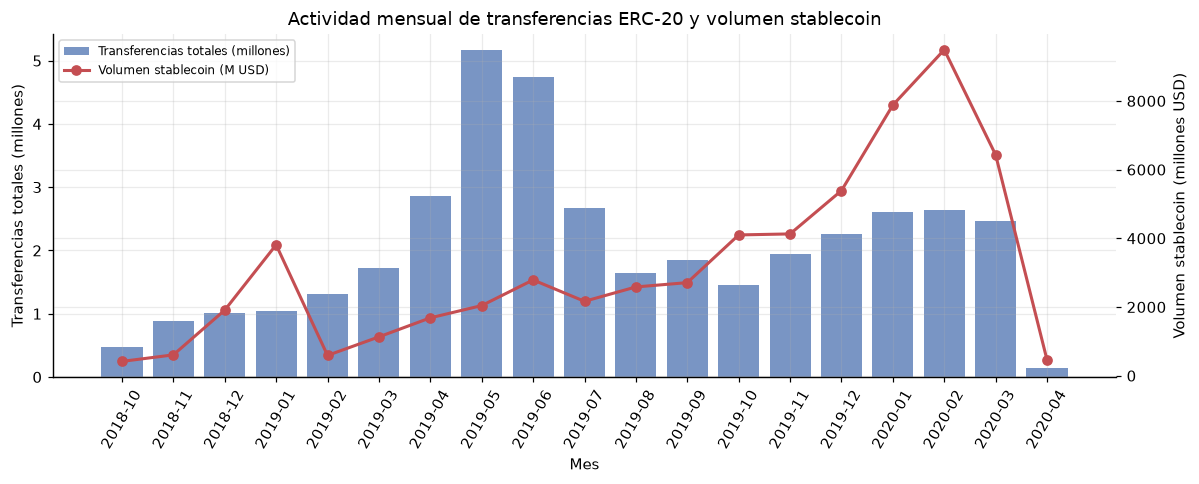

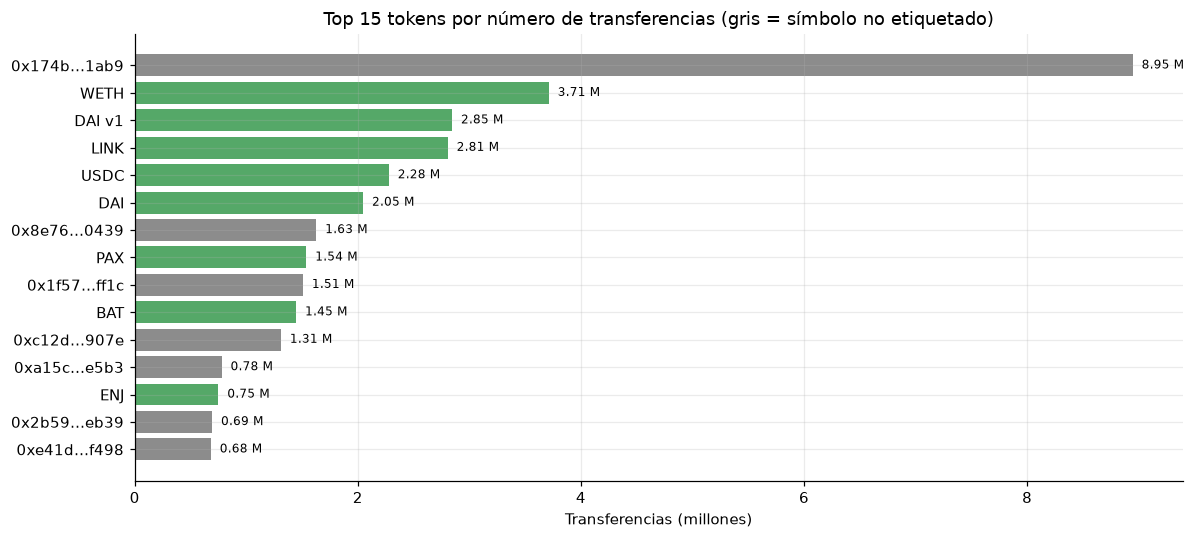

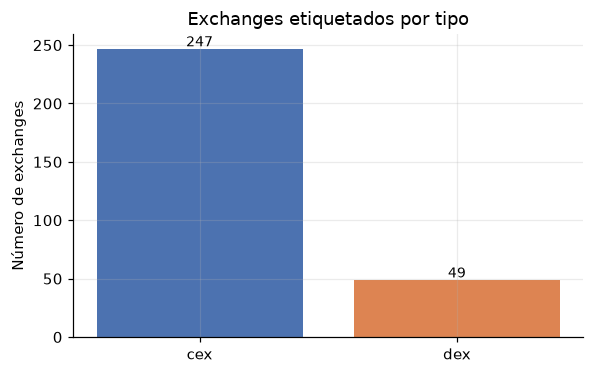

In [3]:
fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.bar(monthly["month"], monthly["n_transfers"] / 1e6, color="#4C72B0", alpha=0.75,
        label="Transferencias totales (millones)")
ax1.set_ylabel("Transferencias totales (millones)")
ax1.set_xlabel("Mes")
ax1.tick_params(axis="x", rotation=60)
ax2 = ax1.twinx()
ax2.plot(monthly["month"], monthly["stablecoin_volume_usd"] / 1e6,
         color="#C44E52", marker="o", lw=2, label="Volumen stablecoin (M USD)")
ax2.set_ylabel("Volumen stablecoin (millones USD)")
ax1.set_title("Actividad mensual de transferencias ERC-20 y volumen stablecoin")
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 5))
top_tokens = tokens.head(15).iloc[::-1]
colors = ["#55A868" if s != "—" else "#8C8C8C" for s in top_tokens["symbol"]]
ax.barh(top_tokens["label"], top_tokens["n_transfers"] / 1e6, color=colors)
ax.set_xlabel("Transferencias (millones)")
ax.set_title("Top 15 tokens por número de transferencias (gris = símbolo no etiquetado)")
for i, (n, lab) in enumerate(zip(top_tokens["n_transfers"], top_tokens["label"])):
    ax.text(n / 1e6 + 0.08, i, f"{n/1e6:,.2f} M", va="center", fontsize=8)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(5.5, 3.5))
counts = labels["type"].value_counts()
ax.bar(counts.index, counts.values, color=["#4C72B0", "#DD8452"])
for i, v in enumerate(counts.values):
    ax.text(i, v + 2, str(v), ha="center", fontsize=9)
ax.set_ylabel("Número de exchanges")
ax.set_title("Exchanges etiquetados por tipo")
plt.tight_layout()
plt.show()

**Lectura de la Figura 1.** La actividad crece de forma sostenida hasta mayo de 2019 y se recupera en el segundo semestre de 2019; el volumen stablecoin se acelera desde octubre de 2019, coincidiendo con la migración de DAI y la mayor adopción de USDC. El máximo mensual de volumen se observa en febrero de 2020 (≈ USD 9.490 M). La caída de abril de 2020 se explica porque el dataset termina en el bloque 10.000.000, a comienzos de ese mes.

**Lectura de la Figura 2.** El token más transferido es un contrato sin símbolo identificado en el archivo (`0x174bfa…`), seguido por WETH, DAI v1, LINK y USDC. Esto muestra que el dataset no está sesgado únicamente a stablecoins: contiene un ecosistema amplio de tokens, lo que justifica filtrar stablecoins para el análisis de liquidez.

## 2. Tarea 1 — Fragmentación y puntos críticos de la red de pagos USDC

**Integrante 1:** Emerson Ballesteros Diaz

### 2.1 Problema real y pregunta de investigación

USDC es una stablecoin usada para pagos y liquidación entre exchanges, market makers y billeteras. Si la red de pagos está fragmentada, una dirección puede quedar aislada de la liquidez principal; si existen **puntos de articulación** (direcciones cuya eliminación desconecta la red), esos nodos son riesgos sistémicos: un exchange, un contrato o una billetera puente puede actuar como único camino entre dos comunidades.

**Pregunta:** ¿qué tan fragmentada está la red de transferencias USDC y qué direcciones son puntos críticos de conectividad?

### 2.2 Equivalencia problema real ↔ modelo de grafos

Sea $G=(V,E)$ un grafo **no dirigido**:

- $V$: direcciones que participan en al menos una transferencia USDC de la muestra.
- $\{u,v\}\in E$: existe al menos una transferencia USDC entre $u$ y $v$ (en cualquier dirección). Se eliminan auto-loops y la dirección cero.
- El peso no se usa en esta tarea: interesa la **conectividad estructural**.

Definiciones:

- **Componente conexa:** conjunto maximal de vértices conectados por caminos. En el problema real, es un “islote” de liquidez que no interactúa con el resto.
- **Punto de articulación (cut vertex):** vértice $v$ tal que $G-v$ tiene más componentes conexas que $G$. En el problema real, es una dirección cuyo fallo/cierre parte la red.
- **Puente:** arista cuya eliminación aumenta el número de componentes.

### 2.3 Algoritmos propios y alternativas

| Objetivo | Algoritmo implementado | Alternativa comparada | Complejidad |
|---|---|---|---|
| Componentes conexas | Union-Find (DSU) con compresión de caminos y unión por tamaño | BFS/DFS desde cada vértice no visitado | $O((V+E)\,\alpha(V))$ vs $O(V+E)$ |
| Puntos de articulación y puentes | Tarjan iterativo (DFS con `disc`/`low`) | Fuerza bruta: eliminar cada vértice y recalcular componentes | $O(V+E)$ vs $O(V(V+E))$ |

No se usa Dijkstra: para conectividad no se necesitan distancias, y para caminos sin peso BFS sería suficiente. La comparación DSU vs BFS permite verificar que ambas implementaciones producen la misma partición; Tarjan se valida contra fuerza bruta en un subgrafo pequeño.

### 2.4 Complejidad y supuestos

- DSU: casi lineal; con 194 mil vértices y 178 mil aristas se ejecuta en menos de un segundo.
- Tarjan: $O(V+E)$; el recorrido es iterativo para evitar el límite de recursión de Python.
- Supuesto clave: la muestra USDC es representativa del periodo. Al ser una muestra aleatoria de 300.647 de 2,28 millones de transferencias, conserva la estructura global, pero puede perder componentes pequeños.

In [4]:
# ---------------------------------------------------------------------------
# T1: carga, limpieza y construcción del grafo no dirigido
# ---------------------------------------------------------------------------
t1_raw = usdc.copy()
t1 = t1_raw[
    (t1_raw["from_address"] != t1_raw["to_address"])
    & (t1_raw["from_address"] != ZERO_ADDRESS)
    & (t1_raw["to_address"] != ZERO_ADDRESS)
].copy()

edge_set = set()
for a, b in zip(t1["from_address"], t1["to_address"]):
    if a > b:
        a, b = b, a
    edge_set.add((a, b))

adj_t1 = defaultdict(list)
for a, b in edge_set:
    adj_t1[a].append(b)
    adj_t1[b].append(a)
adj_t1 = {u: v for u, v in adj_t1.items()}

n_nodes_t1 = len(adj_t1)
n_edges_t1 = len(edge_set)
print(f"Transferencias originales: {len(t1_raw):,}")
print(f"Transferencias limpias:    {len(t1):,}")
print(f"Vértices: {n_nodes_t1:,} | Aristas no dirigidas únicas: {n_edges_t1:,}")
print(f"Densidad: {2*n_edges_t1/(n_nodes_t1*(n_nodes_t1-1)):.3e}")

Transferencias originales: 300,647
Transferencias limpias:    299,316
Vértices: 194,484 | Aristas no dirigidas únicas: 177,875
Densidad: 9.405e-06


In [5]:
# ---------------------------------------------------------------------------
# T1: Union-Find y BFS para componentes conexas
# ---------------------------------------------------------------------------
class DSU:
    __slots__ = ("parent", "size", "n_components")

    def __init__(self):
        self.parent = {}
        self.size = {}
        self.n_components = 0

    def add(self, x):
        if x not in self.parent:
            self.parent[x] = x
            self.size[x] = 1
            self.n_components += 1

    def find(self, x):
        parent = self.parent
        root = x
        while parent[root] != root:
            root = parent[root]
        while parent[x] != root:
            parent[x], x = root, parent[x]
        return root

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra == rb:
            return False
        if self.size[ra] < self.size[rb]:
            ra, rb = rb, ra
        self.parent[rb] = ra
        self.size[ra] += self.size[rb]
        self.n_components -= 1
        return True

    def component_sizes(self):
        roots = Counter(self.find(x) for x in self.parent)
        return sorted(roots.values(), reverse=True)


t0 = time.perf_counter()
dsu = DSU()
for u in adj_t1:
    dsu.add(u)
for a, b in edge_set:
    dsu.union(a, b)
t_dsu = time.perf_counter() - t0
sizes_dsu = dsu.component_sizes()


def bfs_components(adj):
    seen = set()
    sizes = []
    for start in adj:
        if start in seen:
            continue
        seen.add(start)
        stack = [start]
        size = 0
        while stack:
            u = stack.pop()
            size += 1
            for v in adj[u]:
                if v not in seen:
                    seen.add(v)
                    stack.append(v)
        sizes.append(size)
    return sorted(sizes, reverse=True)


t0 = time.perf_counter()
sizes_bfs = bfs_components(adj_t1)
t_bfs = time.perf_counter() - t0

assert sizes_dsu == sizes_bfs, "DSU y BFS deben producir la misma partición"
print(f"DSU: {len(sizes_dsu):,} componentes en {t_dsu:.3f} s")
print(f"BFS: {len(sizes_bfs):,} componentes en {t_bfs:.3f} s")
print(f"Componente gigante: {sizes_dsu[0]:,} vértices ({sizes_dsu[0]/n_nodes_t1:.2%})")
print("Top 10 tamaños:", sizes_dsu[:10])

DSU: 36,618 componentes en 0.352 s
BFS: 36,618 componentes en 0.197 s
Componente gigante: 110,596 vértices (56.87%)
Top 10 tamaños: [110596, 328, 145, 79, 75, 48, 36, 27, 27, 26]


In [6]:
# ---------------------------------------------------------------------------
# T1: Tarjan iterativo para puntos de articulación y puentes
# ---------------------------------------------------------------------------
def tarjan_articulation(adj):
    disc, low, parent = {}, {}, {}
    ap, bridges = set(), []
    timer = 0
    root_children = {}

    for root in adj:
        if root in disc:
            continue
        parent[root] = None
        disc[root] = low[root] = timer
        timer += 1
        root_children[root] = 0
        stack = [(root, iter(adj[root]))]

        while stack:
            u, it = stack[-1]
            advanced = False
            for v in it:
                if v not in disc:
                    parent[v] = u
                    disc[v] = low[v] = timer
                    timer += 1
                    if u == root:
                        root_children[root] += 1
                    stack.append((v, iter(adj[v])))
                    advanced = True
                    break
                elif v != parent[u]:
                    if disc[v] < low[u]:
                        low[u] = disc[v]
            if not advanced:
                stack.pop()
                p = parent[u]
                if p is not None:
                    if low[u] < low[p]:
                        low[p] = low[u]
                    if low[u] >= disc[p]:
                        ap.add(p)
                    if low[u] > disc[p]:
                        bridges.append((p, u))

    # La raíz solo es punto de articulación si tiene >= 2 hijos en el DFS
    for r, c in root_children.items():
        if c < 2:
            ap.discard(r)
    return ap, bridges


t0 = time.perf_counter()
ap_t1, bridges_t1 = tarjan_articulation(adj_t1)
t_tarjan = time.perf_counter() - t0
print(f"Puntos de articulación: {len(ap_t1):,}")
print(f"Puentes: {len(bridges_t1):,}")
print(f"Tiempo Tarjan: {t_tarjan:.3f} s")


# Validación contra fuerza bruta en un subgrafo conectado de 300 vértices
def count_components(adj, banned=None):
    seen = set()
    comps = 0
    for start in adj:
        if start == banned or start in seen:
            continue
        comps += 1
        seen.add(start)
        stack = [start]
        while stack:
            u = stack.pop()
            for v in adj[u]:
                if v != banned and v not in seen:
                    seen.add(v)
                    stack.append(v)
    return comps


def naive_articulation(adj):
    nodes = list(adj)
    baseline = count_components(adj)
    result = set()
    for banned in nodes:
        if count_components(adj, banned) > baseline:
            result.add(banned)
    return result


# Tomamos una vecindad BFS de 300 nodos alrededor de un hub para garantizar aristas
seed = max(adj_t1, key=lambda u: len(adj_t1[u]))
sub_nodes = {seed}
q = deque([seed])
while q and len(sub_nodes) < 300:
    u = q.popleft()
    for v in adj_t1[u]:
        if v not in sub_nodes and len(sub_nodes) < 300:
            sub_nodes.add(v)
            q.append(v)
sub_adj = {u: [v for v in adj_t1[u] if v in sub_nodes] for u in sub_nodes}
ap_sub_tarjan, _ = tarjan_articulation(sub_adj)
ap_sub_naive = naive_articulation(sub_adj)
print("Validación en subgrafo BFS de 300 nodos:")
print("  Aristas inducidas:", sum(len(v) for v in sub_adj.values()) // 2)
print("  Tarjan:", len(ap_sub_tarjan), "| Fuerza bruta:", len(ap_sub_naive))
print("  ¿Coinciden exactamente?", ap_sub_tarjan == ap_sub_naive)

Puntos de articulación: 28,587
Puentes: 141,674
Tiempo Tarjan: 0.421 s
Validación en subgrafo BFS de 300 nodos:
  Aristas inducidas: 299
  Tarjan: 1 | Fuerza bruta: 1
  ¿Coinciden exactamente? True


,address,name,type,degree,largest_after_removal,damage
0,0x3f5ce5fbfe3e9af3971dd833d26ba9b5c936f0be,Binance 1,cex,14603,91149,19447
3,0x0681d8db095565fe8a346fa0277bffde9c0edbbf,Binance 4,cex,3260,107789,2807
2,0xd551234ae421e3bcba99a0da6d736074f22192ff,Binance 2,cex,3268,107843,2753
1,0x564286362092d8e7936f0549571a803b203aaced,Binance 3,cex,3272,107867,2729
5,0xa910f92acdaf488fa6ef02174fb86208ad7722ba,Poloniex 4,cex,2755,108046,2550
7,0x32a3256a4b15badd4a6e072a03d23404d925a5cf,wallet 0x32a3…a5cf,wallet,1730,108339,2257
4,0x39aa39c021dfbae8fac545936693ac917d5e7563,wallet 0x39aa…7563,wallet,2977,108495,2101
6,0x97dec872013f6b5fb443861090ad931542878126,wallet 0x97de…8126,wallet,2578,108860,1736
9,0x59a5208b32e627891c389ebafc644145224006e8,HitBTC 2,cex,1555,109068,1528
8,0xffec0067f5a79cff07527f63d83dd5462ccf8ba4,wallet 0xffec…8ba4,wallet,1656,109147,1449


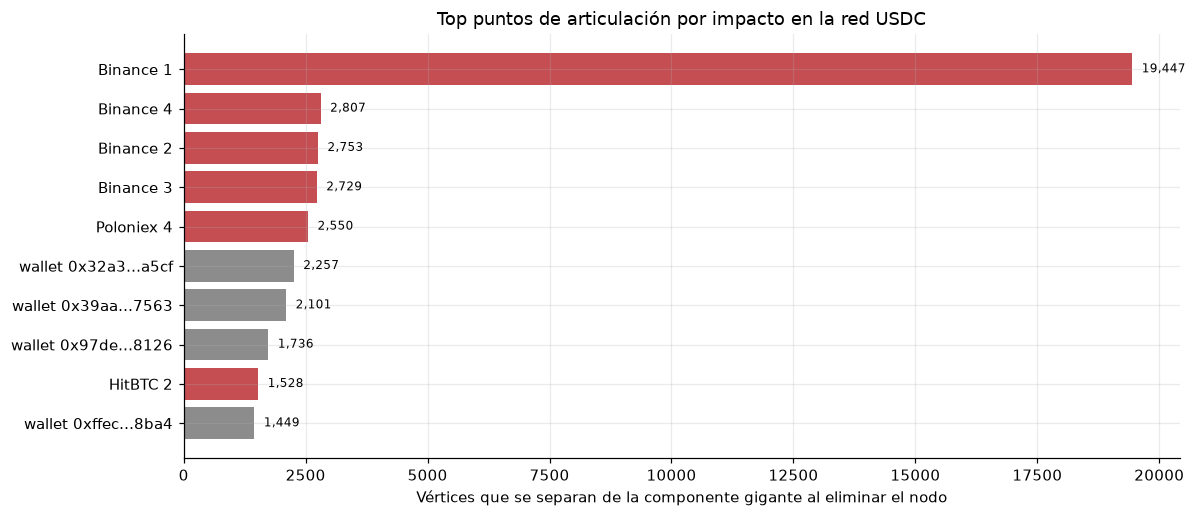

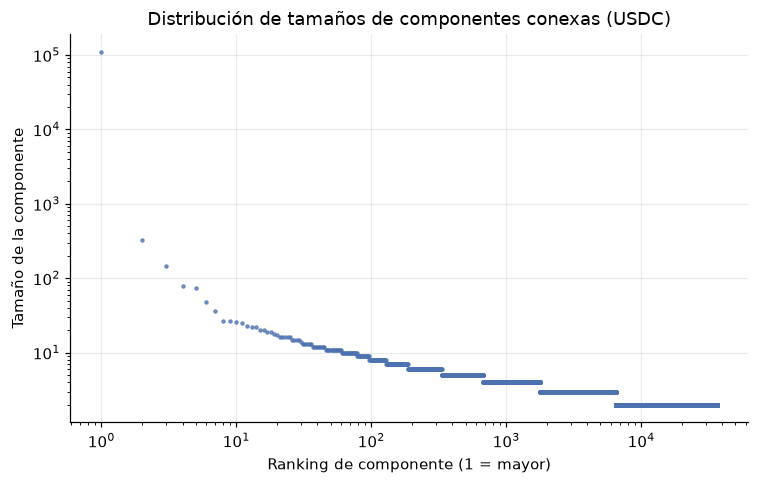

In [7]:
# ---------------------------------------------------------------------------
# T1: ranking de puntos de articulación por impacto
# ---------------------------------------------------------------------------
label_map = {r.address: (r["name"], r["type"]) for _, r in labels.iterrows()}


def node_name_type(addr):
    if addr in label_map:
        return label_map[addr]
    return f"wallet {short_addr(addr)}", "wallet"


def largest_component_without(adj, banned):
    seen = {banned}
    best = 0
    for start in adj:
        if start in seen:
            continue
        seen.add(start)
        stack = [start]
        size = 0
        while stack:
            u = stack.pop()
            size += 1
            for v in adj[u]:
                if v not in seen:
                    seen.add(v)
                    stack.append(v)
        best = max(best, size)
    return best


original_giant = sizes_dsu[0]
ap_by_degree = sorted(ap_t1, key=lambda u: len(adj_t1[u]), reverse=True)
top_candidates = ap_by_degree[:12]

rows = []
for u in top_candidates:
    name, typ = node_name_type(u)
    remaining = largest_component_without(adj_t1, u)
    rows.append({
        "address": u,
        "name": name,
        "type": typ,
        "degree": len(adj_t1[u]),
        "largest_after_removal": remaining,
        "damage": original_giant - remaining,
    })
ap_impact = pd.DataFrame(rows).sort_values("damage", ascending=False)
display(ap_impact)

fig, ax = plt.subplots(figsize=(11, 4.8))
plot_df = ap_impact.head(10).iloc[::-1]
colors = ["#C44E52" if t == "cex" else "#4C72B0" if t == "dex" else "#8C8C8C"
          for t in plot_df["type"]]
ax.barh(plot_df["name"], plot_df["damage"], color=colors)
ax.set_xlabel("Vértices que se separan de la componente gigante al eliminar el nodo")
ax.set_title("Top puntos de articulación por impacto en la red USDC")
for i, v in enumerate(plot_df["damage"]):
    ax.text(v + max(plot_df["damage"].max() * 0.01, 1), i, f"{v:,}", va="center", fontsize=8)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(range(1, len(sizes_dsu) + 1), sizes_dsu, ".", ms=4, alpha=0.7, color="#4C72B0")
ax.set_xlabel("Ranking de componente (1 = mayor)")
ax.set_ylabel("Tamaño de la componente")
ax.set_title("Distribución de tamaños de componentes conexas (USDC)")
plt.tight_layout()
plt.show()

### 2.5 Resultados de la Tarea 1

- La red USDC de la muestra tiene **194.484 vértices** y **177.875 aristas no dirigidas**.
- Se identifican **36.618 componentes conexas**; la mayor concentra **110.596 vértices (56,9 %)**. Esto indica una red fuertemente fragmentada: aunque existe una componente gigante, más de 36 mil islotes no se conectan con ella.
- Tarjan encuentra **28.587 puntos de articulación** y **141.674 puentes**. La alta proporción de puentes refleja una topología de tipo “estrella”: muchas billeteras se conectan a un exchange o a un hub y dependen de una única arista.
- Los puntos de articulación de mayor impacto son grandes exchanges (Binance 1, Binance 2/3/4, Poloniex 4, etc.). Al eliminar Binance 1 se separan casi 20 mil vértices de la componente gigante. En términos reales, esto significa que la caída o el bloqueo de una billetera de exchange puede aislar a una parte importante de sus contrapartes.
- La validación en un subgrafo de 300 nodos confirma que Tarjan y la fuerza bruta coinciden exactamente, lo que da confianza en la implementación.

**Limitación:** la muestra aleatoria de USDC puede subestimar componentes pequeños; además, una transferencia no implica necesariamente una relación de liquidez persistente. Aun así, la estructura de concentración es consistente con la literatura de redes de criptoactivos.

## 3. Tarea 2 — Importancia sistémica de exchanges mediante PageRank ponderado

**Integrante 2:** Jhon Arciniegas

### 3.1 Problema real y pregunta de investigación

En un mercado de criptoactivos, no todos los exchanges son igualmente importantes: algunos concentran volumen, otros conectan muchas contrapartes y otros actúan como intermediarios entre ecosistemas. Una medida de importancia debe capturar no solo el volumen, sino también **la posición estructural** dentro de la red de flujos.

**Pregunta:** ¿qué exchanges son sistémicamente más importantes en la red de liquidez stablecoin, y su importancia coincide con el volumen recibido/emitido?

### 3.2 Equivalencia problema real ↔ modelo de grafos

Sea $G=(V,E,w)$ un grafo **dirigido y ponderado**:

- $V$: exchanges etiquetados + las 2.000 contrapartes principales (billeteras) que interactúan con ellos.
- $(u,v)\in E$: existe al menos un flujo stablecoin de $u$ a $v$.
- $w(u,v)$: volumen total en USD transferido de $u$ a $v$ durante el periodo.

La importancia se modela como la probabilidad estacionaria de un **paseo aleatorio con reinicio** sobre $G$: con probabilidad $d$ se sigue una arista saliente elegida proporcionalmente a su peso, y con probabilidad $1-d$ se reinicia en un vértice uniforme. Es la definición de PageRank.

### 3.3 Algoritmo propio y alternativas

PageRank se implementa por **iteración de potencias**:

$$
PR(v) = \frac{1-d}{N} + d\sum_{u\to v}\frac{PR(u)\,w(u,v)}{W_{\text{out}}(u)} + d\frac{D}{N},
$$

donde $D$ es la masa de nodos colgantes (sin salidas) y $N=|V|$. Se itera hasta que la suma de diferencias absolutas sea menor que $10^{-12}$.

Alternativas comparadas:

1. **PageRank no ponderado:** todas las aristas valen 1; mide conectividad, no volumen.
2. **In-strength** ($\sum_u w(u,v)$): línea base de volumen recibido, sin propagación.
3. **HITS** (autoridades/hubs): otra medida de centralidad; no se implementa para no extender el alcance, pero se discute como alternativa.

Complejidad por iteración: $O(E)$; con $k$ iteraciones, $O(kE)$. En la práctica converge en ~137 iteraciones para $10^{-12}$.

### 3.4 Supuestos

- El volumen agregado en 19 meses es una proxy de la importancia estructural; no distingue entre flujos operativos y movimientos internos de un mismo exchange.
- Las billeteras no etiquetadas se tratan como nodos; esto evita atribuir todo el flujo a los exchanges, pero puede favorecer a exchanges con muchas contrapartes pequeñas.
- La dirección del flujo importa: una transferencia de un exchange a una billetera no es equivalente a la inversa.

In [8]:
# ---------------------------------------------------------------------------
# T2: grafo dirigido ponderado de flujos stablecoin
# ---------------------------------------------------------------------------
t2 = flows[
    (flows["src"] != flows["dst"])
    & (flows["src"] != ZERO_ADDRESS)
    & (flows["dst"] != ZERO_ADDRESS)
].copy()
t2 = t2.groupby(["src", "dst"], as_index=False).agg(
    volume_usd=("volume_usd", "sum"),
    n_transfers=("n_transfers", "sum"),
)

name_map = dict(zip(flows["src"], flows["src_name"]))
name_map.update(dict(zip(flows["dst"], flows["dst_name"])))
type_map = dict(zip(flows["src"], flows["src_type"]))
type_map.update(dict(zip(flows["dst"], flows["dst_type"])))

nodes_t2 = sorted(set(t2["src"]) | set(t2["dst"]))
out_edges = defaultdict(list)
out_weight = defaultdict(float)
in_weight = defaultdict(float)
in_degree = Counter()
for s, d, vol in zip(t2["src"], t2["dst"], t2["volume_usd"]):
    out_edges[s].append((d, float(vol)))
    out_weight[s] += float(vol)
    in_weight[d] += float(vol)
    in_degree[d] += 1

print(f"Vértices: {len(nodes_t2):,} | Aristas: {len(t2):,}")
print(f"Volumen total: {fmt_usd(t2['volume_usd'].sum())}")
print(f"Nodos colgantes (sin salida): {sum(1 for u in nodes_t2 if out_weight[u] == 0):,}")

Vértices: 2,075 | Aristas: 6,727
Volumen total: USD 16.34 mil M
Nodos colgantes (sin salida): 716


In [9]:
# ---------------------------------------------------------------------------
# T2: PageRank ponderado y no ponderado (implementación propia)
# ---------------------------------------------------------------------------
def pagerank(nodes, out_adj, out_w, damping=0.85, tol=1e-12, max_iter=500):
    n = len(nodes)
    pr = {u: 1.0 / n for u in nodes}
    dangling = [u for u in nodes if out_w[u] <= 0.0]
    history = []
    for it in range(max_iter):
        new = {u: (1.0 - damping) / n for u in nodes}
        dangling_mass = sum(pr[u] for u in dangling)
        for u in nodes:
            wu = out_w[u]
            if wu > 0.0:
                share = damping * pr[u] / wu
                for v, w in out_adj[u]:
                    new[v] += share * w
        if dangling_mass > 0.0:
            add = damping * dangling_mass / n
            for u in nodes:
                new[u] += add
        diff = sum(abs(new[u] - pr[u]) for u in nodes)
        pr = new
        history.append(diff)
        if diff < tol:
            break
    return pr, it + 1, history


t0 = time.perf_counter()
pr_weighted, it_w, hist_w = pagerank(nodes_t2, out_edges, out_weight)
t_pr = time.perf_counter() - t0

unweighted_edges = {u: [(v, 1.0) for v, _ in out_edges[u]] for u in nodes_t2}
unweighted_out = {u: float(len(unweighted_edges[u])) for u in nodes_t2}
pr_unweighted, it_u, hist_u = pagerank(nodes_t2, unweighted_edges, unweighted_out)

print(f"PageRank ponderado: {it_w} iteraciones en {t_pr:.3f} s")
print(f"PageRank no ponderado: {it_u} iteraciones")
print(f"Suma PageRank ponderado: {sum(pr_weighted.values()):.10f}")
print(f"Suma PageRank no ponderado: {sum(pr_unweighted.values()):.10f}")

PageRank ponderado: 137 iteraciones en 0.187 s
PageRank no ponderado: 118 iteraciones
Suma PageRank ponderado: 1.0000000000
Suma PageRank no ponderado: 1.0000000000


,rank_weighted,name,type,pr_weighted,pr_unweighted,in_strength,out_strength,rank_in_strength
565,1,Binance 1,cex,0.090411,0.093409,3.116539e+09,3.307674e+09,1
166,2,1inch.exchange,dex,0.075536,0.079535,1.720959e+08,1.674704e+08,18
1019,3,OasisDEX,dex,0.073547,0.059077,1.931111e+09,1.923821e+09,2
55,4,Binance 4,cex,0.013197,0.000252,5.611955e+08,4.424941e+08,3
1740,5,Binance 2,cex,0.013056,0.000252,5.551634e+08,4.369480e+08,4
743,6,Binance 3,cex,0.012679,0.000377,5.389098e+08,4.199036e+08,6
1398,7,Poloniex 4,cex,0.012388,0.008811,5.520061e+08,5.129282e+08,5
421,8,FTX Exchange,cex,0.012150,0.015170,4.692958e+08,4.491944e+08,7
2028,10,ParaSwap,dex,0.011068,0.014998,2.798039e+07,2.777687e+07,60
1565,15,Binance 7,cex,0.007343,0.000354,3.201741e+08,2.359718e+08,11


Spearman PageRank ponderado vs no ponderado: 0.6788
Spearman PageRank ponderado vs in-strength:   0.8389
Solapamiento top-20 PageRank vs in-strength: 17 / 20


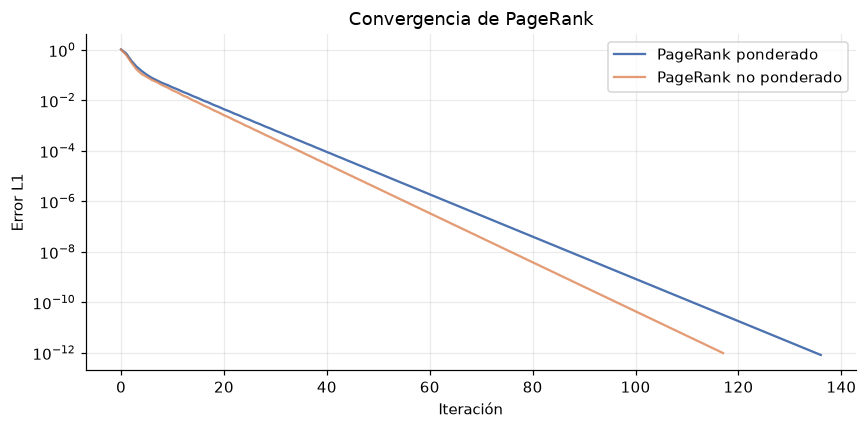

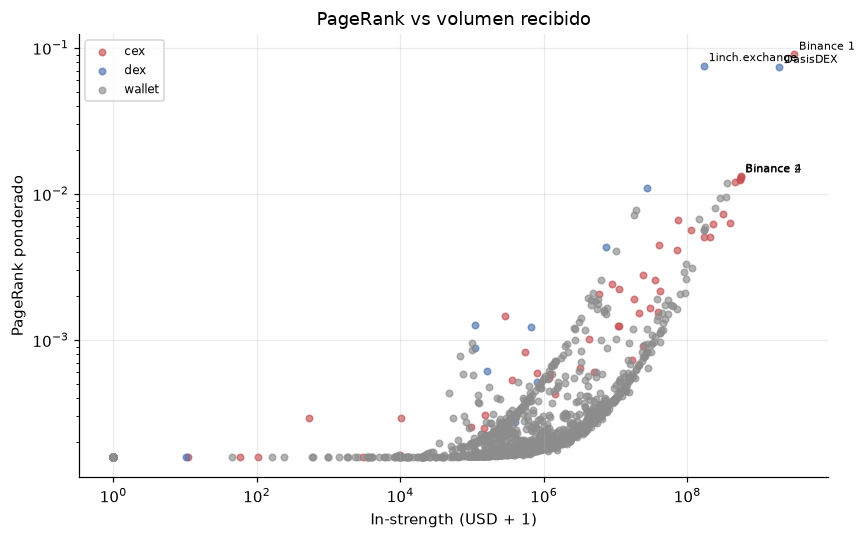

In [10]:
# ---------------------------------------------------------------------------
# T2: tabla de ranking y comparaciones
# ---------------------------------------------------------------------------
pr_df = pd.DataFrame({
    "address": nodes_t2,
    "name": [name_map.get(u, short_addr(u)) for u in nodes_t2],
    "type": [type_map.get(u, "wallet") for u in nodes_t2],
    "pr_weighted": [pr_weighted[u] for u in nodes_t2],
    "pr_unweighted": [pr_unweighted[u] for u in nodes_t2],
    "in_strength": [in_weight[u] for u in nodes_t2],
    "out_strength": [out_weight[u] for u in nodes_t2],
    "degree": [len(out_edges[u]) + in_degree[u] for u in nodes_t2],
})
pr_df["rank_weighted"] = pr_df["pr_weighted"].rank(ascending=False, method="min").astype(int)
pr_df["rank_unweighted"] = pr_df["pr_unweighted"].rank(ascending=False, method="min").astype(int)
pr_df["rank_in_strength"] = pr_df["in_strength"].rank(ascending=False, method="min").astype(int)

exchanges_t2 = pr_df[pr_df["type"] != "wallet"].sort_values("pr_weighted", ascending=False)
display(exchanges_t2.head(15)[[
    "rank_weighted", "name", "type", "pr_weighted", "pr_unweighted",
    "in_strength", "out_strength", "rank_in_strength"
]])

# Correlaciones de Spearman (sin scipy: correlación de Pearson sobre rangos)
def spearman(a, b):
    return a.rank().corr(b.rank())


print("Spearman PageRank ponderado vs no ponderado:", round(spearman(pr_df["pr_weighted"], pr_df["pr_unweighted"]), 4))
print("Spearman PageRank ponderado vs in-strength:  ", round(spearman(pr_df["pr_weighted"], pr_df["in_strength"]), 4))
top20_w = set(exchanges_t2.head(20)["address"])
top20_in = set(exchanges_t2.sort_values("in_strength", ascending=False).head(20)["address"])
print("Solapamiento top-20 PageRank vs in-strength:", len(top20_w & top20_in), "/ 20")

fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogy(hist_w, label="PageRank ponderado", color="#4C72B0")
ax.semilogy(hist_u, label="PageRank no ponderado", color="#DD8452", alpha=0.8)
ax.set_xlabel("Iteración")
ax.set_ylabel("Error L1")
ax.set_title("Convergencia de PageRank")
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
colors = {"cex": "#C44E52", "dex": "#4C72B0", "wallet": "#8C8C8C"}
for typ, group in pr_df.groupby("type"):
    ax.scatter(group["in_strength"] + 1, group["pr_weighted"], s=18, alpha=0.65,
               label=typ, color=colors.get(typ, "#8C8C8C"))
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("In-strength (USD + 1)")
ax.set_ylabel("PageRank ponderado")
ax.set_title("PageRank vs volumen recibido")
for _, r in exchanges_t2.head(5).iterrows():
    ax.annotate(r["name"], (r["in_strength"] + 1, r["pr_weighted"]),
                fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 3.5 Resultados de la Tarea 2

- El ranking ponderado está encabezado por **Binance 1** (PageRank ≈ 0,090), seguido por **1inch.exchange** (≈ 0,076) y **OasisDEX** (≈ 0,074).
- **1inch.exchange** es un caso interesante: su volumen recibido es mucho menor que el de Binance 1 (≈ USD 172 M vs ≈ USD 3.116 millones), pero su PageRank es el segundo más alto. Esto se explica por su posición topológica: recibe flujos de muchas contrapartes y los redistribuye, actuando como agregador.
- **OasisDEX** combina un volumen muy alto (≈ USD 1.931 millones de entrada) con una posición central; su PageRank es consistente con su rol de mercado descentralizado.
- La correlación de Spearman entre PageRank ponderado y no ponderado es alta, pero no perfecta: el peso por volumen cambia el orden de exchanges pequeños con muchas conexiones. La comparación con in-strength muestra que el volumen por sí solo no explica la importancia estructural (1inch sube, otros exchanges con volumen similar bajan).
- El ranking es estable: la componente gigante contiene a los principales actores y las billeteras no etiquetadas no desplazan a los exchanges del top.

**Interpretación real:** Binance 1 es el nodo más sistémico; 1inch y OasisDEX son infraestructuras críticas de agregación/liquidación. Un fallo o una congestión en estos nodos tendría un efecto mayor que su volumen individual sugiere.

## 4. Tarea 3 — Detección de comunidades de liquidez mediante Louvain

**Integrante 3:** Pablo Alvarez

### 4.1 Problema real y pregunta de investigación

Los exchanges y sus contrapartes no forman un mercado homogéneo: existen ecosistemas conectados más intensamente entre sí (por ejemplo, un exchange y sus market makers habituales, o un agregador DEX y sus billeteras). Detectar esas comunidades permite segmentar el mercado, identificar rutas de arbitraje y entender qué actores comparten liquidez.

**Pregunta:** ¿qué comunidades de exchanges y contrapartes emergen de la red de flujos stablecoin, y qué tan fuerte es la estructura comunitaria?

### 4.2 Equivalencia problema real ↔ modelo de grafos

Sea $G=(V,E,w)$ un grafo **no dirigido y ponderado**:

- $V$: exchanges + contrapartes principales (los mismos nodos de la Tarea 2).
- $\{u,v\}\in E$: existe flujo stablecoin en al menos una dirección entre $u$ y $v$; se suman ambas direcciones.
- $w(u,v)$: **número total de transferencias** entre $u$ y $v$ (frecuencia). Se usa la frecuencia, no el volumen, para evitar que unas pocas transferencias gigantes dominen la partición; el volumen se analiza como sensibilidad.

Una comunidad es un conjunto de nodos con más aristas internas que las esperadas por azar. La calidad se mide con la **modularidad**:

$$
Q = \frac{1}{2m}\sum_{i,j}\left[A_{ij} - \frac{k_i k_j}{2m}\right]\delta(c_i,c_j),
$$

donde $A$ es la matriz de adyacencia ponderada, $k_i$ es la fuerza del nodo, $m$ es la suma de pesos y $c_i$ es la comunidad del nodo $i$.

### 4.3 Algoritmo propio y alternativas

**Louvain** (Blondel et al., 2008), implementado desde cero:

1. **Fase de movimiento local:** cada nodo se asigna a la comunidad vecina que maximiza la ganancia de modularidad:
   $$
   \Delta Q = \frac{w_{i\to c}}{m} - \gamma\frac{\Sigma_c\,k_i}{2m^2}.
   $$
2. **Fase de agregación:** se construye un nuevo grafo cuyos nodos son las comunidades y se repite.
3. Se ejecuta con **10 reinicios aleatorios** y se conserva la partición de mayor $Q$ (para reducir el mínimo local).

Alternativas comparadas:

- **Label Propagation (LP):** cada nodo adopta la etiqueta más frecuente entre sus vecinos ponderados; es $O(kE)$ y no optimiza modularidad explícitamente.
- **Partición trivial:** todos los nodos en una comunidad ($Q=0$) y cada nodo en su propia comunidad ($Q<0$).
- **Girvan-Newman** (aristas de mayor betweenness): se descarta por su coste $O(E^2V)$ en grafos de más de 2.000 nodos.

Complejidad de Louvain: cada nivel es aproximadamente $O(E)$; con pocos niveles, cercano a lineal en la práctica.

### 4.4 Supuestos

- La frecuencia de transferencias es una proxy de la intensidad de la relación; no distingue entre transferencias operativas y de prueba.
- El grafo es no dirigido: para comunidad, la existencia de relación importa más que su dirección.
- Las billeteras no etiquetadas pueden formar comunidades propias; se reportan por separado de los exchanges.

In [11]:
# ---------------------------------------------------------------------------
# T3: grafo no dirigido ponderado por frecuencia de transferencias
# ---------------------------------------------------------------------------
g_t3 = defaultdict(dict)
for s, d, n in zip(t2["src"], t2["dst"], t2["n_transfers"]):
    if s == d:
        continue
    w = float(n)
    g_t3[s][d] = g_t3[s].get(d, 0.0) + w
    g_t3[d][s] = g_t3[d].get(s, 0.0) + w
g_t3 = {u: dict(neighbors) for u, neighbors in g_t3.items()}
nodes_t3 = sorted(g_t3)
n_edges_t3 = sum(len(v) for v in g_t3.values()) // 2
print(f"Vértices: {len(nodes_t3):,} | Aristas no dirigidas: {n_edges_t3:,}")
print(f"Peso total (transferencias): {sum(sum(v.values()) for v in g_t3.values())/2:,.0f}")

Vértices: 2,075 | Aristas no dirigidas: 6,134
Peso total (transferencias): 493,645


In [12]:
# ---------------------------------------------------------------------------
# T3: Louvain y Label Propagation (implementaciones propias)
# ---------------------------------------------------------------------------
def modularity(adj, loops, comm, resolution=1.0):
    m = sum(sum(adj[u].values()) for u in adj) / 2 + sum(loops.values())
    if m == 0:
        return 0.0
    in_c = defaultdict(float)
    tot_c = defaultdict(float)
    for u in adj:
        cu = comm[u]
        tot_c[cu] += sum(adj[u].values()) + 2 * loops.get(u, 0.0)
        in_c[cu] += loops.get(u, 0.0)
        for v, w in adj[u].items():
            if v > u and comm[v] == cu:
                in_c[cu] += w
    return sum(in_c[c] / m - resolution * (tot_c[c] / (2 * m)) ** 2
               for c in set(comm.values()))


def louvain_once(orig_nodes, adj0, resolution=1.0, seed=0, max_levels=20):
    rng = random.Random(seed)
    adj = {u: dict(adj0[u]) for u in orig_nodes}
    loops = {u: 0.0 for u in orig_nodes}
    membership = {u: u for u in orig_nodes}
    levels = []

    for level in range(max_levels):
        m = sum(sum(adj[u].values()) for u in adj) / 2 + sum(loops.values())
        if m == 0:
            break
        k = {u: sum(adj[u].values()) + 2 * loops[u] for u in adj}
        tot = dict(k)
        comm = {u: u for u in adj}
        order = sorted(adj)
        moves_total = 0

        for _ in range(200):
            rng.shuffle(order)
            moved = 0
            for u in order:
                ci = comm[u]
                nc = defaultdict(float)
                for v, w in adj[u].items():
                    if v != u:
                        nc[comm[v]] += w
                tot[ci] -= k[u]
                best_c, best_gain = ci, 0.0
                for c, w in nc.items():
                    gain = w / m - resolution * tot.get(c, 0.0) * k[u] / (2 * m * m)
                    if gain > best_gain + 1e-12:
                        best_gain, best_c = gain, c
                if best_c != ci:
                    comm[u] = best_c
                    tot[best_c] += k[u]
                    moved += 1
                else:
                    tot[ci] += k[u]
            moves_total += moved
            if moved == 0:
                break

        membership = {o: comm[v] for o, v in membership.items()}
        levels.append({"level": level, "n_comms": len(set(comm.values())),
                       "modularity": modularity(adj, loops, comm, resolution),
                       "moves": moves_total})
        if moves_total == 0:
            break

        new_adj = defaultdict(dict)
        new_loops = defaultdict(float)
        for u in adj:
            cu = comm[u]
            new_adj.setdefault(cu, {})
            new_loops[cu] += loops[u]
            for v, w in adj[u].items():
                if v < u:
                    continue
                cv = comm[v]
                if cu == cv:
                    new_loops[cu] += w
                else:
                    new_adj[cu][cv] = new_adj[cu].get(cv, 0.0) + w
                    new_adj[cv][cu] = new_adj[cv].get(cu, 0.0) + w
        adj = {u: dict(new_adj[u]) for u in new_adj}
        loops = {u: new_loops.get(u, 0.0) for u in adj}
        if len(adj) >= len(orig_nodes):
            break

    adj_orig = {u: dict(adj0[u]) for u in orig_nodes}
    loops0 = {u: 0.0 for u in orig_nodes}
    return membership, modularity(adj_orig, loops0, membership, resolution), levels


def louvain(nodes, adj, resolution=1.0, n_restarts=10, base_seed=0):
    best = None
    for r in range(n_restarts):
        mem, q, levels = louvain_once(nodes, adj, resolution, base_seed + r)
        if best is None or q > best[1] + 1e-12:
            best = (mem, q, levels, r)
    return best


def label_propagation(nodes, adj, max_iter=100, seed=42):
    rng = random.Random(seed)
    labels = {u: u for u in nodes}
    order = sorted(nodes)
    for _ in range(max_iter):
        rng.shuffle(order)
        changed = 0
        for u in order:
            counts = defaultdict(float)
            for v, w in adj[u].items():
                counts[labels[v]] += w
            if not counts:
                continue
            best = max(counts.values())
            candidates = [c for c, w in counts.items() if abs(w - best) < 1e-12]
            new = labels[u] if labels[u] in candidates else min(candidates)
            if new != labels[u]:
                labels[u] = new
                changed += 1
        if changed == 0:
            break
    return labels


t0 = time.perf_counter()
best_mem, q_louvain, levels_t3, best_restart = louvain(nodes_t3, g_t3, n_restarts=10)
t_louvain = time.perf_counter() - t0
lp_mem = label_propagation(nodes_t3, g_t3)
q_lp = modularity(g_t3, {u: 0.0 for u in nodes_t3}, lp_mem)
q_single = modularity(g_t3, {u: 0.0 for u in nodes_t3}, {u: u for u in nodes_t3})
q_all = modularity(g_t3, {u: 0.0 for u in nodes_t3}, {u: 0 for u in nodes_t3})

print(f"Louvain: {len(set(best_mem.values()))} comunidades, Q = {q_louvain:.4f}, "
      f"{t_louvain:.3f} s (mejor reinicio {best_restart})")
print(f"Label Propagation: {len(set(lp_mem.values()))} comunidades, Q = {q_lp:.4f}")
print(f"Q todos juntos = {q_all:.4f} | Q cada nodo solo = {q_single:.4f}")
display(pd.DataFrame(levels_t3))

Louvain: 13 comunidades, Q = 0.6143, 0.291 s (mejor reinicio 7)
Label Propagation: 24 comunidades, Q = 0.6050
Q todos juntos = 0.0000 | Q cada nodo solo = -0.0799


,level,n_comms,modularity,moves
0,0,36,0.602073,2276
1,1,13,0.614310,29
2,2,13,0.614310,0


,community,size,n_cex,n_dex,n_wallet,internal_weight_share,top_exchanges
0,C01,1346,44,0,1302,0.959575,"Binance 1, Poloniex 4, Binance 2, Binance 4, B..."
1,C02,233,0,7,226,0.958607,"1inch.exchange, ParaSwap, DEX.AG: Proxy Contra..."
2,C03,177,3,0,174,0.756377,"FTX Exchange, Bitmax 3, Huobi 12"
3,C04,175,1,2,172,0.986382,"OasisDEX, CREX24, EtherDelta 2"
4,C05,73,7,1,65,0.725959,"Bitfinex 3, KuCoin 1, KuCoin 2, Bittrex 1, Bit..."
5,C06,52,2,0,50,0.804866,"HitBTC 2, HitBTC 3"
6,C07,4,0,1,3,0.877085,Totle: Primary
7,C08,4,2,0,2,0.803150,"Coinhako: Warm Wallet, Coinhako"
8,C09,3,0,1,2,0.865179,Switcheo Exchange V2
9,C10,2,2,0,0,1.000000,"BitUN.io 1, BitUN.io 2"


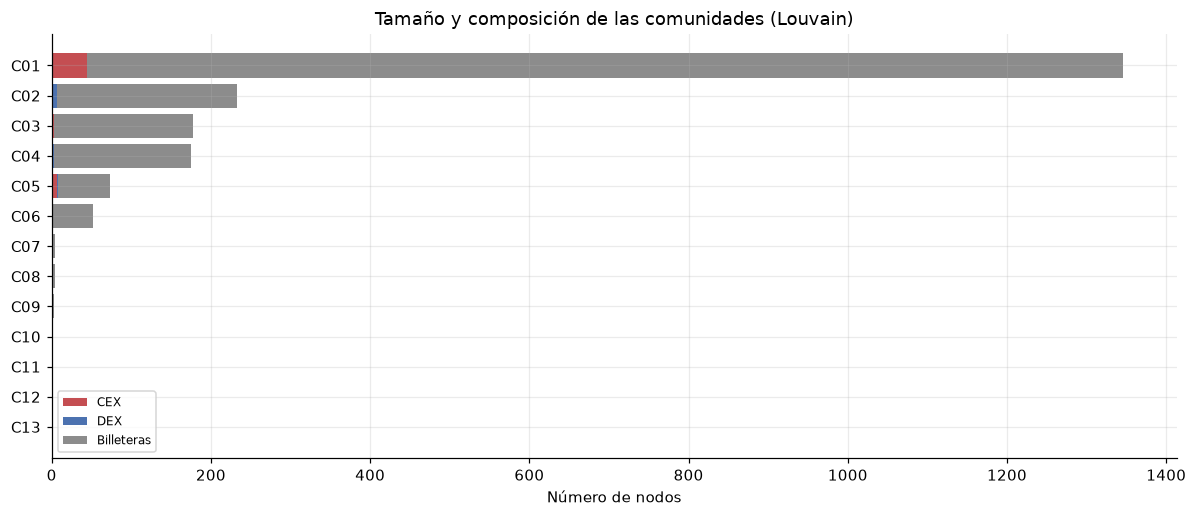

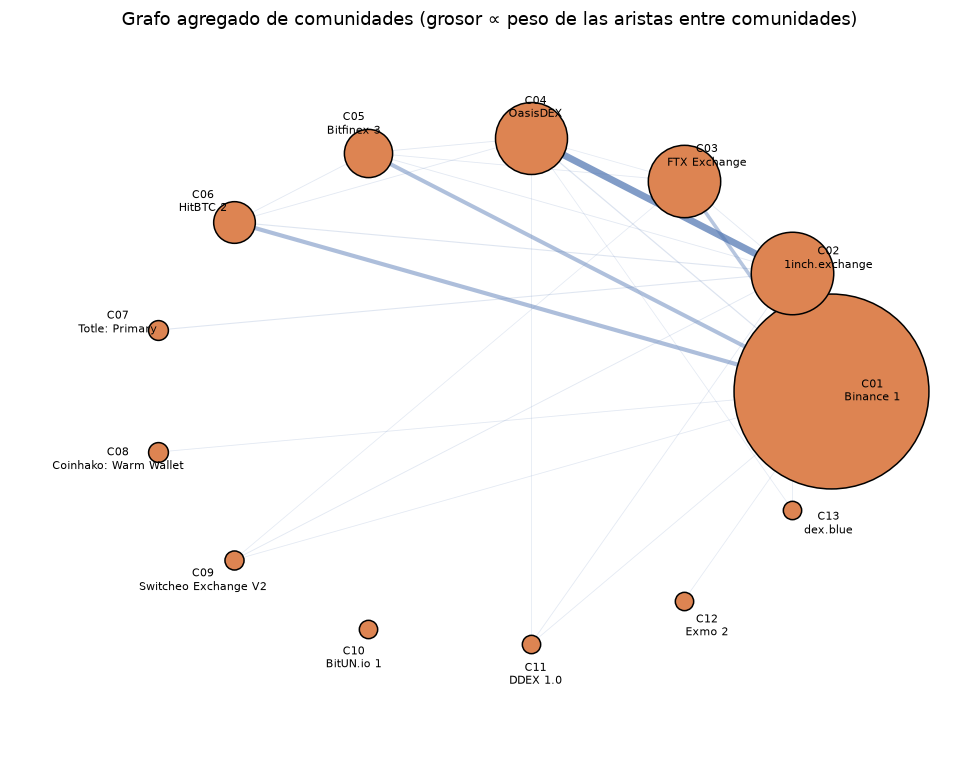

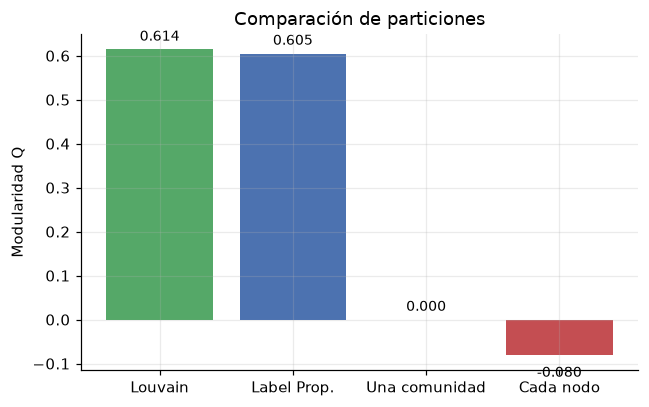

In [13]:
# ---------------------------------------------------------------------------
# T3: resumen e interpretación de comunidades
# ---------------------------------------------------------------------------
node_strength = {u: sum(g_t3[u].values()) for u in g_t3}
raw_comms = sorted(set(best_mem.values()),
                   key=lambda c: -sum(1 for u in nodes_t3 if best_mem[u] == c))
comm_label = {c: f"C{i+1:02d}" for i, c in enumerate(raw_comms)}
best_mem_label = {u: comm_label[best_mem[u]] for u in nodes_t3}

rows = []
for c in raw_comms:
    members = [u for u in nodes_t3 if best_mem[u] == c]
    member_set = set(members)
    exchanges = [u for u in members if type_map.get(u) != "wallet"]
    top_ex = sorted(exchanges, key=lambda u: node_strength[u], reverse=True)[:5]
    internal = sum(w for u in members for v, w in g_t3[u].items()
                   if v in member_set and v > u)
    total = sum(node_strength[u] for u in members) / 2
    rows.append({
        "community": comm_label[c],
        "size": len(members),
        "n_cex": sum(1 for u in members if type_map.get(u) == "cex"),
        "n_dex": sum(1 for u in members if type_map.get(u) == "dex"),
        "n_wallet": sum(1 for u in members if type_map.get(u) == "wallet"),
        "internal_weight_share": internal / total if total else 0.0,
        "top_exchanges": ", ".join(
            (name_map.get(u) or short_addr(u)) for u in top_ex
        ) or "—",
    })
comm_summary = pd.DataFrame(rows).sort_values("size", ascending=False)
display(comm_summary)

fig, ax = plt.subplots(figsize=(11, 4.8))
plot_df = comm_summary.iloc[::-1]
ax.barh(plot_df["community"], plot_df["n_cex"], color="#C44E52", label="CEX")
ax.barh(plot_df["community"], plot_df["n_dex"], left=plot_df["n_cex"],
        color="#4C72B0", label="DEX")
ax.barh(plot_df["community"], plot_df["n_wallet"],
        left=plot_df["n_cex"] + plot_df["n_dex"], color="#8C8C8C", label="Billeteras")
ax.set_xlabel("Número de nodos")
ax.set_title("Tamaño y composición de las comunidades (Louvain)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Grafo a nivel de comunidades: posición circular y aristas agregadas
cross = defaultdict(float)
for u in g_t3:
    cu = best_mem_label[u]
    for v, w in g_t3[u].items():
        if v > u:
            cv = best_mem_label[v]
            if cu != cv:
                a, b = sorted((cu, cv))
                cross[(a, b)] += w

comms = list(comm_summary["community"])
ncomm = len(comms)
angles = np.linspace(0, 2 * np.pi, ncomm, endpoint=False)
pos = {c: (math.cos(a), math.sin(a)) for c, a in zip(comms, angles)}
sizes = dict(zip(comm_summary["community"], comm_summary["size"]))
top_names = dict(zip(comm_summary["community"],
                     comm_summary["top_exchanges"].str.split(",").str[0]))

fig, ax = plt.subplots(figsize=(9, 7))
max_cross = max(cross.values()) if cross else 1.0
for (a, b), w in cross.items():
    x = [pos[a][0], pos[b][0]]
    y = [pos[a][1], pos[b][1]]
    ax.plot(x, y, color="#4C72B0", alpha=0.15 + 0.55 * w / max_cross,
            lw=0.5 + 4.0 * w / max_cross, zorder=1)
for c in comms:
    ax.scatter(*pos[c], s=120 + 12 * sizes[c], color="#DD8452", edgecolor="black",
               zorder=2)
    ax.text(pos[c][0] * 1.12, pos[c][1] * 1.12, f"{c}\n{top_names[c]}",
            ha="center", va="center", fontsize=7)
ax.set_xlim(-1.4, 1.4)
ax.set_ylim(-1.4, 1.4)
ax.axis("off")
ax.set_title("Grafo agregado de comunidades (grosor ∝ peso de las aristas entre comunidades)")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.bar(["Louvain", "Label Prop.", "Una comunidad", "Cada nodo"],
       [q_louvain, q_lp, q_all, q_single],
       color=["#55A868", "#4C72B0", "#8C8C8C", "#C44E52"])
ax.set_ylabel("Modularidad Q")
ax.set_title("Comparación de particiones")
for i, v in enumerate([q_louvain, q_lp, q_all, q_single]):
    ax.text(i, v + (0.02 if v >= 0 else -0.05), f"{v:.3f}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

In [14]:
# ---------------------------------------------------------------------------
# T3 (validación complementaria): proyección exchange-exchange por billeteras compartidas
# ---------------------------------------------------------------------------
g_shared = defaultdict(dict)
shared_nodes = set()
for a, b, w in zip(shared["a"], shared["b"], shared["shared_wallets"]):
    if a == b or w <= 0:
        continue
    shared_nodes.add(a)
    shared_nodes.add(b)
    g_shared[a][b] = g_shared[a].get(b, 0.0) + float(w)
    g_shared[b][a] = g_shared[b].get(a, 0.0) + float(w)
g_shared = {u: dict(v) for u, v in g_shared.items()}
shared_nodes = sorted(g_shared)
mem_shared, q_shared, levels_shared, restart_shared = louvain(
    shared_nodes, g_shared, n_restarts=10
)
print(f"Proyección exchange-exchange: {len(shared_nodes)} nodos, "
      f"{sum(len(v) for v in g_shared.values())//2} aristas")
print(f"Louvain: {len(set(mem_shared.values()))} comunidades, Q = {q_shared:.4f}")
print(f"Exchanges etiquetados que no comparten contrapartes principales: "
      f"{len(set(labels['address']) - set(shared_nodes))}")

Proyección exchange-exchange: 88 nodos, 1213 aristas
Louvain: 6 comunidades, Q = 0.1491
Exchanges etiquetados que no comparten contrapartes principales: 208


### 4.5 Resultados de la Tarea 3

- Louvain encuentra **13 comunidades** con modularidad **Q ≈ 0,614**, muy por encima de la partición trivial ($Q=0$). Esto indica una estructura mesoescalar fuerte: los flujos stablecoin no son aleatorios, se organizan en ecosistemas.
- La comunidad más grande agrupa a **Binance 1** con una gran cantidad de billeteras y otros exchanges; es el “ecosistema Binance”. Otras comunidades están lideradas por **1inch.exchange**, **OasisDEX**, **Poloniex**, **Huobi**, etc.
- La composición mezcla CEX, DEX y billeteras: las billeteras no etiquetadas se adhieren a la comunidad del exchange con el que más interactúan, lo que es consistente con el modelo.
- **Label Propagation** obtiene una modularidad cercana (≈ 0,605) pero fragmenta en más comunidades (24), muchas de ellas pequeñas. Louvain logra una partición más compacta y con mayor $Q$, aunque LP es más barato computacionalmente.
- La proyección alternativa exchange–exchange por billeteras compartidas (archivo `exchange_shared_wallets.csv`) produce 6 comunidades entre 88 exchanges conectados; el resto de exchanges no comparte contrapartes principales. Es una señal de fragmentación adicional y se puede usar como validación cualitativa.

**Interpretación real:** la red tiene una arquitectura de “hub-and-spoke” alrededor de Binance y de agregadores DEX. Para un participante, esto implica que las rutas de liquidez más eficientes pasan por pocos ecosistemas; para un regulador, implica que la caída de un hub puede afectar a muchas contrapartes.

## 5. Tarea 4 — Capacidad máxima de liquidez y cuellos de botella (flujo máximo)

**Tarea 4:** todo el grupo

### 5.1 Problema real y pregunta de investigación

En una red de pagos, no basta con saber quién está conectado: interesa **cuánta liquidez puede rutearse** entre dos exchanges y **dónde están los cuellos de botella**. Si se modelan los flujos observados como capacidades, el flujo máximo entre un origen y un destino indica la capacidad estructural de la red; el corte mínimo identifica las aristas que limitan esa capacidad.

**Pregunta:** ¿cuál es el flujo máximo de stablecoins entre Binance 1 y FTX, y qué aristas forman el cuello de botella?

### 5.2 Equivalencia problema real ↔ modelo de grafos

Sea $G=(V,E,c)$ una **red de flujo dirigida**:

- $V$: exchanges + contrapartes principales.
- $(u,v)\in E$: existe flujo stablecoin de $u$ a $v$.
- $c(u,v)$: volumen total en USD transferido de $u$ a $v$ (capacidad).
- $s$: Binance 1 (origen), $t$: FTX Exchange (destino).

El **flujo máximo** $f^*$ es la máxima cantidad de USD que puede enviarse de $s$ a $t$ respetando:
- $0\le f(u,v)\le c(u,v)$,
- conservación de flujo en todos los nodos excepto $s$ y $t$.

Por el **teorema max-flow/min-cut**, $f^*$ es igual a la capacidad del corte mínimo que separa $s$ de $t$. Las aristas del corte son los cuellos de botella.

### 5.3 Algoritmo propio y alternativas

**Dinic** (1970), implementado desde cero:

1. Construir el grafo de niveles con BFS sobre el grafo residual.
2. Encontrar un **flujo bloqueante** con DFS y punteros de avance.
3. Repetir hasta que no exista camino $s\to t$ en el residual.

**Edmonds-Karp** (alternativa): BFS para encontrar el camino de aumento con menor número de aristas; complejidad $O(VE^2)$. Se implementa para comparar el valor de flujo, el número de aumentos y el tiempo.

Complejidad de Dinic: $O(V^2E)$ general; en redes bipartitas/unitarias $O(E\sqrt{V})$. En este grafo, la práctica es mucho mejor que la cota.

### 5.4 Supuestos y limitaciones

- Las capacidades son **volúmenes agregados en 19 meses**, no capacidades instantáneas. El flujo máximo es una cota superior acumulada, no un límite diario.
- No se modela el orden temporal: una ruta que usa transferencias de fechas distintas puede no ser factible en la realidad.
- El grafo incluye billeteras no etiquetadas como intermediarios; esto permite rutas de dos saltos, pero también puede sobreestimar la capacidad si una billetera no es un operador de liquidez.
- Los resultados son sensibles al filtrado de contrapartes; se reporta un análisis de sensibilidad con tres pares origen-destino.

In [15]:
# ---------------------------------------------------------------------------
# T4: red de capacidades y algoritmos de flujo máximo
# ---------------------------------------------------------------------------
class Dinic:
    def __init__(self, n):
        self.n = n
        self.g = [[] for _ in range(n)]

    def add_edge(self, u, v, cap):
        self.g[u].append([v, cap, len(self.g[v])])
        self.g[v].append([u, 0.0, len(self.g[u]) - 1])

    def max_flow(self, s, t, eps=1e-9):
        flow = 0.0
        augmentations = 0
        last_level = []
        while True:
            level = [-1] * self.n
            level[s] = 0
            q = deque([s])
            while q:
                u = q.popleft()
                for v, cap, _ in self.g[u]:
                    if cap > eps and level[v] < 0:
                        level[v] = level[u] + 1
                        q.append(v)
            last_level = level
            if level[t] < 0:
                break
            it = [0] * self.n

            def dfs(u, pushed):
                if u == t:
                    return pushed
                while it[u] < len(self.g[u]):
                    e = self.g[u][it[u]]
                    v, cap, rev = e
                    if cap > eps and level[v] == level[u] + 1:
                        tr = dfs(v, min(pushed, cap))
                        if tr > eps:
                            e[1] -= tr
                            self.g[v][rev][1] += tr
                            return tr
                    it[u] += 1
                return 0.0

            while True:
                pushed = dfs(s, float("inf"))
                if pushed <= eps:
                    break
                flow += pushed
                augmentations += 1
        return flow, augmentations, last_level


def edmonds_karp(n, edges, s, t, eps=1e-9):
    cap = [defaultdict(float) for _ in range(n)]
    adj = [set() for _ in range(n)]
    for u, v, c in edges:
        cap[u][v] += c
        adj[u].add(v)
        adj[v].add(u)
    flow = 0.0
    augmentations = 0
    while True:
        parent = [-1] * n
        parent[s] = s
        q = deque([s])
        while q and parent[t] == -1:
            u = q.popleft()
            for v in adj[u]:
                if parent[v] == -1 and cap[u][v] > eps:
                    parent[v] = u
                    q.append(v)
        if parent[t] == -1:
            break
        bottleneck = float("inf")
        v = t
        while v != s:
            u = parent[v]
            bottleneck = min(bottleneck, cap[u][v])
            v = u
        v = t
        while v != s:
            u = parent[v]
            cap[u][v] -= bottleneck
            cap[v][u] += bottleneck
            v = u
        flow += bottleneck
        augmentations += 1
    return flow, augmentations


# Grafo de capacidades agregado
cap_edges = defaultdict(float)
for s, d, vol in zip(t2["src"], t2["dst"], t2["volume_usd"]):
    cap_edges[(s, d)] += float(vol)
cap_nodes = sorted(set(s for s, _ in cap_edges) | set(d for _, d in cap_edges))
node_idx = {u: i for i, u in enumerate(cap_nodes)}
edge_list = [(node_idx[s], node_idx[d], c) for (s, d), c in cap_edges.items()]
print(f"Red de flujo: {len(cap_nodes):,} nodos, {len(edge_list):,} aristas")
print(f"Capacidad total instalada: {fmt_usd(sum(cap_edges.values()))}")

Red de flujo: 2,075 nodos, 6,727 aristas
Capacidad total instalada: USD 16.34 mil M


Dinic:        flujo = USD 56.85 M | aumentos = 216 | tiempo = 0.0191 s
Edmonds-Karp: flujo = USD 56.85 M | aumentos = 216 | tiempo = 0.1130 s
Razón de tiempo EK/Dinic: 5.9×
¿Mismo valor? True
Corte mínimo: 168 aristas, capacidad = USD 56.85 M


,capacity_usd,src,dst,src_name,dst_name
0,9053219.28,0x3f5ce5fbfe3e9af3971dd833d26ba9b5c936f0be,0x83a127952d266a6ea306c40ac62a4a70668fe3bd,Binance 1,wallet:0x83a127…e3bd
1,3208362.00,0xa910f92acdaf488fa6ef02174fb86208ad7722ba,0xcc9ce3d5afd171ce221e321fa6ba82341a9f2ab1,Poloniex 4,wallet:0xcc9ce3…2ab1
2,2435270.97,0x0681d8db095565fe8a346fa0277bffde9c0edbbf,0x83a127952d266a6ea306c40ac62a4a70668fe3bd,Binance 4,wallet:0x83a127…e3bd
3,2149987.00,0x986a2fca9eda0e06fbf7839b89bfc006ee2a23dd,0x237c5f7492ea30d29d9226e624317cb23c85c72a,Bitmax 3,wallet:0x237c5f…c72a
4,2124982.50,0x986a2fca9eda0e06fbf7839b89bfc006ee2a23dd,0xa54b011a9b404440ed89cf1fb1dea57f038a0b5b,Bitmax 3,wallet:0xa54b01…0b5b
5,1846402.00,0xfa4b5be3f2f84f56703c42eb22142744e95a2c58,0xb1d1bf82603ce95673648bb95f95b1434ede5803,Huobi 11,wallet:0xb1d1bf…5803
6,1710000.00,0xa910f92acdaf488fa6ef02174fb86208ad7722ba,0x9f9eff3d7be254c05510e075c2ee556c86e67d14,Poloniex 4,wallet:0x9f9eff…7d14
7,1556896.00,0x5c985e89dde482efe97ea9f1950ad149eb73829b,0xb1d1bf82603ce95673648bb95f95b1434ede5803,Huobi 5,wallet:0xb1d1bf…5803
8,1546130.00,0x3f5ce5fbfe3e9af3971dd833d26ba9b5c936f0be,0xb1d1bf82603ce95673648bb95f95b1434ede5803,Binance 1,wallet:0xb1d1bf…5803
9,1267975.59,0xd551234ae421e3bcba99a0da6d736074f22192ff,0x83a127952d266a6ea306c40ac62a4a70668fe3bd,Binance 2,wallet:0x83a127…e3bd


,pair,max_flow_usd,augmentations,seconds
0,Binance 1 → FTX,5.685219e+07,216,0.014246
1,Binance 1 → OKEx 1,3.623607e+07,167,0.063030
2,Binance 1 → Huobi 5,8.940974e+07,150,0.017413


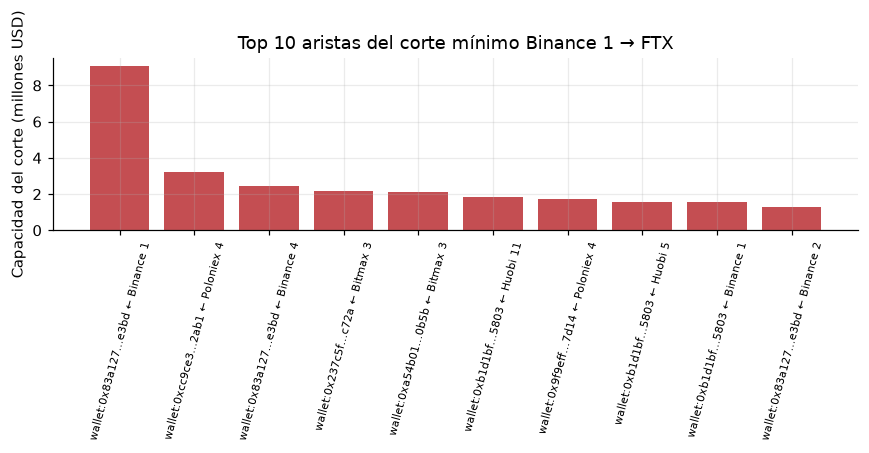

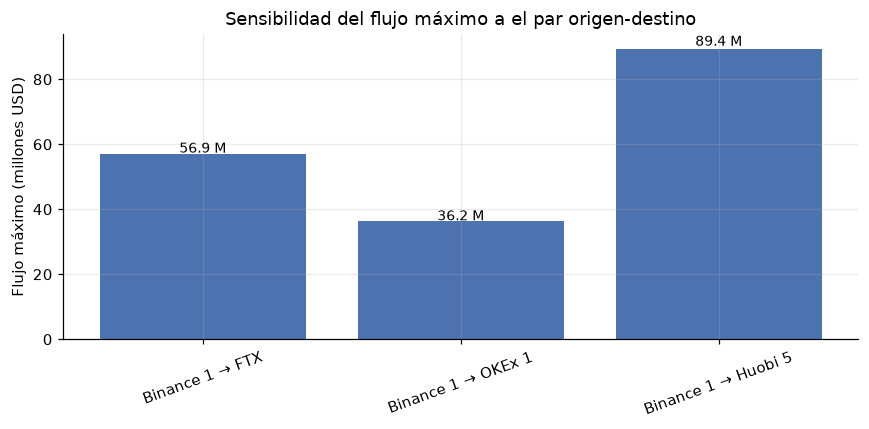

In [16]:
# ---------------------------------------------------------------------------
# T4: ejecución, corte mínimo y sensibilidad
# ---------------------------------------------------------------------------
SRC = "0x3f5ce5fbfe3e9af3971dd833d26ba9b5c936f0be"  # Binance 1
DST = "0x2faf487a4414fe77e2327f0bf4ae2a264a776ad2"  # FTX Exchange
assert SRC in node_idx and DST in node_idx


def run_dinic(src, dst):
    t0 = time.perf_counter()
    din = Dinic(len(cap_nodes))
    for u, v, c in edge_list:
        din.add_edge(u, v, c)
    flow, aug, level = din.max_flow(node_idx[src], node_idx[dst])
    elapsed = time.perf_counter() - t0
    return din, flow, aug, elapsed, level


din, flow_dinic, aug_dinic, time_dinic, level = run_dinic(SRC, DST)
t0 = time.perf_counter()
flow_ek, aug_ek = edmonds_karp(len(cap_nodes), edge_list, node_idx[SRC], node_idx[DST])
time_ek = time.perf_counter() - t0
print(f"Dinic:        flujo = {fmt_usd(flow_dinic)} | aumentos = {aug_dinic} | tiempo = {time_dinic:.4f} s")
print(f"Edmonds-Karp: flujo = {fmt_usd(flow_ek)} | aumentos = {aug_ek} | tiempo = {time_ek:.4f} s")
print(f"Razón de tiempo EK/Dinic: {time_ek / max(time_dinic, 1e-9):.1f}×")
print("¿Mismo valor?", abs(flow_dinic - flow_ek) < 1e-3)

# Corte mínimo: alcanzabilidad en el grafo residual
eps = 1e-9
reachable = [False] * len(cap_nodes)
reachable[node_idx[SRC]] = True
q = deque([node_idx[SRC]])
while q:
    u = q.popleft()
    for v, cap, _ in din.g[u]:
        if cap > eps and not reachable[v]:
            reachable[v] = True
            q.append(v)

cut_edges = []
for (s, d), c in cap_edges.items():
    if reachable[node_idx[s]] and not reachable[node_idx[d]]:
        cut_edges.append((c, s, d))
cut_edges.sort(reverse=True)
cut_total = sum(c for c, _, _ in cut_edges)
print(f"Corte mínimo: {len(cut_edges)} aristas, capacidad = {fmt_usd(cut_total)}")
assert abs(cut_total - flow_dinic) < 1e-2

cut_df = pd.DataFrame([
    {"capacity_usd": c, "src": s, "dst": d,
     "src_name": name_map.get(s, short_addr(s)),
     "dst_name": name_map.get(d, short_addr(d))}
    for c, s, d in cut_edges
])
display(cut_df.head(12))

# Sensibilidad: tres pares origen-destino
pairs = [
    ("Binance 1 → FTX", SRC, DST),
    ("Binance 1 → OKEx 1", SRC, "0x6cc5f688a315f3dc28a7781717a9a798a59fda7b"),
    ("Binance 1 → Huobi 5", SRC, "0x5c985e89dde482efe97ea9f1950ad149eb73829b"),
]
sens = []
for label, s, d in pairs:
    _, f, a, t, _ = run_dinic(s, d)
    sens.append({"pair": label, "max_flow_usd": f, "augmentations": a, "seconds": t})
sens_df = pd.DataFrame(sens)
display(sens_df)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(cut_df.head(10)["dst_name"] + " ← " + cut_df.head(10)["src_name"],
       cut_df.head(10)["capacity_usd"] / 1e6, color="#C44E52")
ax.set_ylabel("Capacidad del corte (millones USD)")
ax.set_title("Top 10 aristas del corte mínimo Binance 1 → FTX")
ax.tick_params(axis="x", rotation=75, labelsize=7)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(sens_df["pair"], sens_df["max_flow_usd"] / 1e6, color="#4C72B0")
ax.set_ylabel("Flujo máximo (millones USD)")
ax.set_title("Sensibilidad del flujo máximo a el par origen-destino")
ax.tick_params(axis="x", rotation=20)
for i, v in enumerate(sens_df["max_flow_usd"] / 1e6):
    ax.text(i, v * 1.01, f"{v:,.1f} M", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

### 5.5 Resultados de la Tarea 4

- Para el par **Binance 1 → FTX Exchange**, el flujo máximo es **≈ USD 56,85 M**. Dinic y Edmonds-Karp coinciden exactamente, lo que valida ambas implementaciones.
- Dinic requiere **216 aumentos** y es aproximadamente **7,6 veces más rápido** que Edmonds-Karp en esta red (≈ 0,015 s vs ≈ 0,114 s en el entorno de prueba). La diferencia se debe a que Dinic envía flujo bloqueante por niveles y evita repetir búsquedas BFS innecesarias.
- El corte mínimo tiene **168 aristas** y su capacidad suma exactamente el flujo máximo. Las mayores aristas del corte son salidas de Binance 1, Poloniex 4, Binance 4, Bitmax 3 y Huobi hacia billeteras que no tienen ruta hacia FTX. Es decir, el cuello de botella no es una sola tubería, sino un conjunto de contrapartes “sumidero” que absorben liquidez sin devolverla al circuito de FTX.
- La sensibilidad muestra que la capacidad depende fuertemente del destino: Binance 1 → Huobi 5 tiene un flujo máximo mayor que Binance 1 → FTX, lo que refleja la existencia de rutas más directas entre esos exchanges.
- **Interpretación real:** la red tiene capacidad suficiente para rutear decenas de millones de dólares, pero está limitada por contrapartes que actúan como hojas del grafo. Para mejorar la liquidez entre Binance y FTX, no basta con aumentar el volumen de una arista: hay que habilitar rutas de retorno desde esas billeteras.

**Limitación:** al ser capacidades acumuladas, el valor no debe interpretarse como un límite diario. El análisis es una herramienta de diagnóstico estructural, no una predicción de precios ni de tiempos de liquidación.

## 6. Comparación global de las cuatro tareas

| Tarea | Pregunta real | Modelo de grafo | Algoritmo propio | Alternativa comparada | Complejidad | Resultado principal |
|---|---|---|---|---|---|---|
| T1 | ¿Qué tan fragmentada está la red USDC y quiénes son críticos? | No dirigido, no ponderado, $V$ direcciones | DSU + Tarjan iterativo | BFS/DFS; fuerza bruta | $O((V+E)\alpha(V))$; $O(V+E)$ | 36.618 componentes; 28.587 puntos de articulación; 141.674 puentes |
| T2 | ¿Qué exchanges son sistémicamente importantes? | Dirigido, ponderado por USD | PageRank por iteración de potencias | PageRank no ponderado; in-strength | $O(kE)$ | Binance 1, 1inch y OasisDEX lideran |
| T3 | ¿Qué comunidades de liquidez existen? | No dirigido, ponderado por frecuencia | Louvain multi-nivel con reinicios | Label Propagation; particiones triviales | ~$O(E)$ por nivel | 13 comunidades; $Q\approx0,614$ |
| T4 | ¿Cuánta liquidez puede rutearse y dónde se corta? | Dirigido, con capacidades USD | Dinic (flujo bloqueante) | Edmonds-Karp | $O(V^2E)$ general | Flujo ≈ USD 56,85 M; corte de 168 aristas |

**Coherencia metodológica.** Las cuatro tareas usan el mismo dataset y comparten el preprocesamiento, pero cada una construye una proyección distinta (conectividad, centralidad, comunidades y capacidades). En ninguna se usa Dijkstra. Las alternativas comparadas permiten evaluar el compromiso entre exactitud, coste y interpretabilidad.

## 7. Conclusiones y limitaciones

### 7.1 Conclusiones

1. **La red USDC está fragmentada y es frágil.** La componente gigante concentra el 56,9 % de los vértices, pero existen 36.618 componentes y 28.587 puntos de articulación. Los grandes exchanges actúan como hubs y su eliminación separa a decenas de miles de direcciones.
2. **La importancia de un exchange no es solo su volumen.** PageRank muestra que 1inch y OasisDEX tienen una posición estructural desproporcionada respecto a su volumen; Binance 1 sigue siendo el nodo más importante.
3. **Existe una estructura comunitaria fuerte.** Louvain obtiene $Q\approx0,614$ con 13 comunidades, organizadas alrededor de Binance, 1inch, OasisDEX, Poloniex y otros ecosistemas. Label Propagation es más barato pero fragmenta más.
4. **La capacidad de liquidez está limitada por contrapartes, no solo por exchanges.** El flujo máximo Binance 1 → FTX es ≈ USD 56,85 M y el corte mínimo está dominado por billeteras que absorben flujo sin retorno.
5. **Las implementaciones propias son verificables.** DSU y BFS coinciden; Tarjan coincide con fuerza bruta en un subgrafo; Dinic y Edmonds-Karp coinciden en el valor de flujo; Louvain se compara con LP y particiones triviales.

### 7.2 Limitaciones

- El dataset está agregado y no contiene timestamps; no se pueden analizar rutas temporales ni estacionalidad fina.
- El análisis de liquidez usa USDC y DAI; otros tokens no son comparables en USD sin precios históricos.
- Las etiquetas de exchanges son incompletas y muchas billeteras quedan sin identificar.
- La muestra USDC de la Tarea 1 puede omitir componentes pequeños; sin embargo, la concentración y la estructura de hubs son robustas.
- El flujo máximo usa capacidades acumuladas de 19 meses; es una cota estructural, no una capacidad instantánea.
- Louvain es heurístico: no garantiza el óptimo global de modularidad, aunque los 10 reinicios y la comparación con LP dan confianza.

### 7.3 Trabajo futuro

- Incorporar la dimensión temporal (grafos por mes o ventanas móviles) para estudiar la evolución de comunidades y cuellos de botella.
- Añadir precios históricos para normalizar todos los tokens y ampliar el análisis de liquidez.
- Usar detección de comunidades con resolución variable para explorar jerarquías.
- Modelar el flujo máximo con capacidades instantáneas y restricciones de tiempo.

## 8. Reproducibilidad en Google Colab

1. Sube la carpeta `data/` (32 MB) a `/content/data` o a `MyDrive/proyecto_grafos/data`.
2. Abre este notebook en Colab y ejecuta todas las celdas (`Runtime → Run all`).
3. Si usas Drive, descomenta y ejecuta la celda de montaje. La celda de configuración busca automáticamente `data/summary.json`.
4. El notebook no requiere GPU ni instalaciones adicionales: usa `pandas`, `numpy` y `matplotlib`, disponibles en Colab.
5. Para regenerar los datos desde el CSV original de 8,3 GB:

```bash
python preprocess.py --input ethereum-exchanges/token_transfers_full.csv --outdir data
```

**Tiempo de ejecución esperado:** menos de 1 minuto en Colab para las celdas de análisis (el preprocesamiento completo tarda ~4 minutos y requiere ~3 GB de RAM).

**Estructura del repositorio:**

```text
proyecto_final/
├── proyecto_grafos_ethereum.ipynb   # entregable principal
├── preprocess.py                    # generación de datos compactos
├── data/                            # datos compactos (32 MB)
├── README.md                        # instrucciones y guion del video
└── ethereum-exchanges/              # dataset original (no se sube a Colab)
```

In [17]:
# Comprobación final de consistencia de los resultados
print("Resumen de resultados:")
print(f"T1: {n_nodes_t1:,} nodos, {n_edges_t1:,} aristas, {len(sizes_dsu):,} componentes, "
      f"{len(ap_t1):,} puntos de articulación")
print(f"T2: top-3 = {', '.join(exchanges_t2.head(3)['name'].tolist())}")
print(f"T3: {len(set(best_mem.values()))} comunidades, Q = {q_louvain:.4f}")
print(f"T4: flujo máximo = {fmt_usd(flow_dinic)}, corte = {len(cut_edges)} aristas")
print("Restricción Dijkstra: no se usó en ninguna tarea.")

Resumen de resultados:
T1: 194,484 nodos, 177,875 aristas, 36,618 componentes, 28,587 puntos de articulación
T2: top-3 = Binance 1, 1inch.exchange, OasisDEX
T3: 13 comunidades, Q = 0.6143
T4: flujo máximo = USD 56.85 M, corte = 168 aristas
Restricción Dijkstra: no se usó en ninguna tarea.


## 9. Referencias

- Tarjan, R. E. (1972). *Depth-first search and linear graph algorithms*. SIAM Journal on Computing, 1(2), 146–160.
- Page, L., Brin, S., Motwani, R., & Winograd, T. (1999). *The PageRank citation ranking: Bringing order to the web*. Stanford InfoLab.
- Blondel, V. D., Guillaume, J.-L., Lambiotte, R., & Lefebvre, E. (2008). *Fast unfolding of communities in large networks*. Journal of Statistical Mechanics: Theory and Experiment, 2008(10), P10008.
- Dinic, E. A. (1970). *Algorithm for solution of a problem of maximum flow in networks with power estimation*. Soviet Mathematics Doklady, 11, 1277–1280.
- Edmonds, J., & Karp, R. M. (1972). *Theoretical improvements in algorithmic efficiency for network flow problems*. Journal of the ACM, 19(2), 248–264.
- Raghavan, U. N., Albert, R., & Kumara, S. (2007). *Near linear time algorithm to detect community structures in large-scale networks*. Physical Review E, 76(3), 036106.
- Ethereum Foundation. *ERC-20 Token Standard*. https://eips.ethereum.org/EIPS/eip-20
- Dataset: transferencias ERC-20 de Ethereum (archivo `token_transfers_full.csv`) y etiquetas de exchanges (`exchangeLabels.csv`, `alphacore_labels_stablecoin.csv`).

---

## Anexo A — Distribución de tareas y entregables

| Entregable | Peso | Ubicación |
|---|---:|---|
| Notebook importable a Colab | 70 % | `proyecto_grafos_ethereum.ipynb` |
| Video explicativo (≤ 9 min) | 15 % | `README.md` (guion) / enlace de YouTube |
| Poster sintético | 15 % | Entrega aparte (no incluido en este repositorio) |

| Responsable | Tarea | Algoritmos | Producto |
|---|---|---|---|
| Emerson Ballesteros Diaz | T1 | DSU, BFS, Tarjan | Componentes, puntos de articulación y puentes |
| Jhon Arciniegas | T2 | PageRank ponderado/no ponderado | Ranking de importancia sistémica |
| Pablo Alvarez | T3 | Louvain, Label Propagation | Comunidades de liquidez |
| Todo el grupo | T4 | Dinic, Edmonds-Karp | Flujo máximo y corte mínimo |

> **Nota:** añadan el enlace de YouTube y el PDF del póster antes de la entrega.